# 05 Agent grading

**What this does.** The agent loop (Fiona, with Riya) grades each target-comp pair 0/1/2 with the team's rubric. In up
to four steps it may search either company's saved website, search the web, or answer; a grade must cite shown lines
from both companies. The target is treated as private; no figures, multiples, similarity or rank reach the model.
With facet scores (11-12) it also rates 11 facets 0/25/50/75/100 (null = no evidence, never 0), and
`agent_ranking.py` (Fiona, with Barbara's scoring standard) turns them into coverage C, observed similarity S and
evidence points E, then the final order: agent grade, then S, then B3.

**Status.** Ported as is. Barbara's scoring standard and the ranking built on it are **pending Michael's review**.
Valuation of these lists is in `08_valuation` (`agent_valuation.py`); this component never reads EV/EBITDA.

**Changelog**
- 2026-11-18: created from `v1/AGENT_LOOP.md` and the agent runs. Default candidates are now the current B3 list
  (v1 defaulted to the Haiku B3 run). The saved ranking and its evaluation reproduce exactly.
- 2026-11-19: section 3.4 ported from `v1/notebooks/peer_evaluation.ipynb` section 7.2 (outcome counts,
  fit dimensions) on the current verdicts, with the 0-2 rubric; plus the dimensions by Barbara's grade.


In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "v2" / "current.toml").exists())
sys.path.insert(0, str(ROOT / "v2" / "common"))
import paths, nbtools as nb
paths.setup()
import pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_rows", 80)
cur = paths.current()
checks = nb.Checks()

In [2]:
import json, cohorts
pd.Series(cur["agent_grading"])

run               outputs-local/v1a/05_agent_grading/ranking_45targets_sonnet
model                                                                  sonnet
prompt_version                                                    2026-11-05b
facet_scores                                                             True
dtype: object

## 2. Inputs

In [3]:
run = paths.path(cur["agent_grading"]["run"])
R = cur["agent_grading"]["run"] + "/"
nb.inputs([R + "verdicts.csv", R + "pairs.csv", R + "instructions.txt"])

,input,rows,sha256,status
0,outputs-local/v1a/05_agent_grading/ranking_45targets_sonnet/verdicts.csv,293.0,0dd990f9ba05,matches seed
1,outputs-local/v1a/05_agent_grading/ranking_45targets_sonnet/pairs.csv,293.0,3b9b6a446c24,matches seed
2,outputs-local/v1a/05_agent_grading/ranking_45targets_sonnet/instructions.txt,NaN,5b6bcf69f5fb,matches seed


## 3. Results

### 3.1 The run

In [4]:
config = json.loads((run / "config.json").read_text())
v = pd.read_csv(run / "verdicts.csv", dtype={"target": str, "comp": str})
print(f"{len(v)} pairs, {v['target'].nunique()} targets; model {config['model']}, prompt {config['prompt_version']}, "
      f"facet scores {config['facet_scores']}, web search {config['search']}")
pd.Series({"status ok": int(v["status"].eq("ok").sum()), "grade 2": int((v["score"] == 2).sum()),
           "grade 1": int((v["score"] == 1).sum()), "grade 0": int((v["score"] == 0).sum()),
           "insufficient evidence": int(v["score"].isna().sum()),
           "mean lookups per pair": round(v["lookups"].mean(), 2),
           "pairs with a web search": int((v["web_searches"] > 0).sum())}).to_frame("value")

293 pairs, 45 targets; model sonnet, prompt 2026-11-05b, facet scores True, web search claude


,value
status ok,293.00
grade 2,26.00
grade 1,157.00
grade 0,107.00
insufficient evidence,3.00
mean lookups per pair,0.25
pairs with a web search,30.00


### 3.2 Against Barbara's grades (`dev_293`)

In [5]:
dev = cohorts.load("dev_293")
d = dev.merge(v[["target", "comp", "score"]], left_on=["target_id", "comp_id"], right_on=["target", "comp"])
g = d.dropna(subset=["score"])
print(f"{len(d)} pairs, {len(g)} graded by the agent; exact {(g.score == g.grade).mean():.1%}, "
      f"peer vs non-peer {((g.score >= 1) == (g.grade >= 1)).mean():.1%}")
pd.crosstab(d["grade"], d["score"].map(lambda s: "insufficient" if pd.isna(s) else int(s)),
            rownames=["Barbara"], colnames=["agent"])

293 pairs, 290 graded by the agent; exact 80.0%, peer vs non-peer 83.8%


agent,0,1,2,insufficient
Barbara,,,,
0,75,15,0,1
1,32,138,7,1
2,0,4,19,1


### 3.3 Ranking (C / S / E): orderings against Barbara's labels

In [6]:
import agent_ranking as ar
ranked = ar.rank(v[v["status"] == "ok"])
labels = pd.read_csv(paths.src("06_labels", "barbara_293", "review", "pairs.csv"), dtype={"target_id": str, "comp_id": str})
ev = ar.evaluate(ranked, labels, "score_barbara")
print(f"mean evidence coverage {ev['mean_coverage']}%; Spearman with the label: S {ev['spearman_S_vs_label']}, "
      f"E {ev['spearman_E_vs_label']}, B3 {ev['spearman_B3_vs_label']}")
rows = [{"ordering": name, "k": k, **{m: r[m] for m in ("pairwise_accuracy", "precision_at_k", "peers_in_top_k")}}
        for k, by in ev["by_k"].items() for name, r in by.items()]
pd.DataFrame(rows).pivot(index="ordering", columns="k", values=["pairwise_accuracy", "precision_at_k"]).round(3)

mean evidence coverage 59.5%; Spearman with the label: S 0.635, E 0.531, B3 0.523


pairwise_accuracy               precision_at_k              
k                                     3      6      7              3      6      7
ordering                                                                          
B3                                0.816  0.816  0.816          0.800  0.731  0.714
E                                 0.787  0.787  0.787          0.800  0.735  0.706
S                                 0.867  0.867  0.867          0.822  0.752  0.725
agent_0_1_2                       0.879  0.879  0.879          0.830  0.752  0.729
final (agent, then S)             0.886  0.886  0.886          0.822  0.752  0.729

In [7]:
facets = [c for c in v.columns if c.startswith("facet_") and c not in ("facet_scores", "facet_weights")]
ok = v[v["status"] == "ok"]
ok[facets].notna().mean().round(2).rename(lambda c: c.removeprefix("facet_")).rename("share of pairs with evidence").to_frame().T

,primary_products,primary_services,customer_segment,end_markets,business_model,revenue_model,value_chain_position,geography_served,specialization,distribution_channels,regulatory_exposure
share of pairs with evidence,0.71,0.48,0.75,0.8,0.95,0.12,0.75,0.46,0.6,0.16,0.11


### 3.4 Outcomes and business-fit dimensions (from v1 `peer_evaluation.ipynb`)

Section 7.2 of `v1/notebooks/peer_evaluation.ipynb` (10-27; it read the 0-3 evaluator's run on v0's cosine -> LLM
pairs) on the agent's verdicts of the 293 pairs: how many pairs get each grade, and how often each business-fit dimension is a match,
partial, mismatch or unknown. v1a adds the same dimensions split by Barbara's grade (row % per grade).

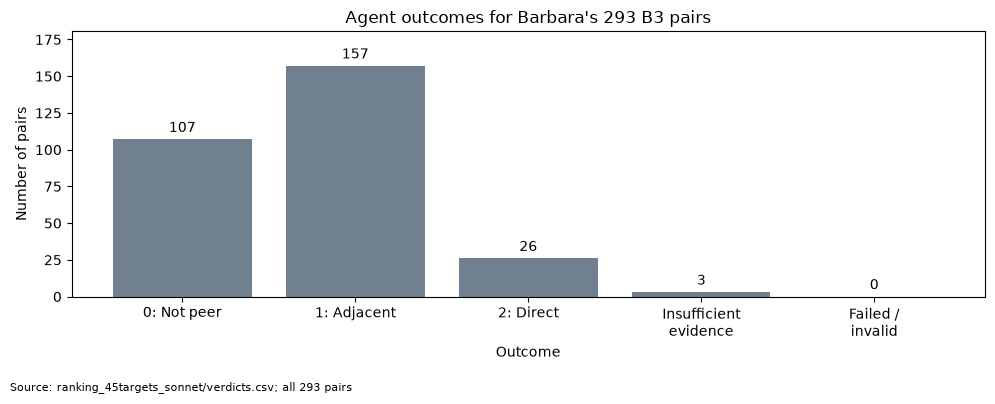

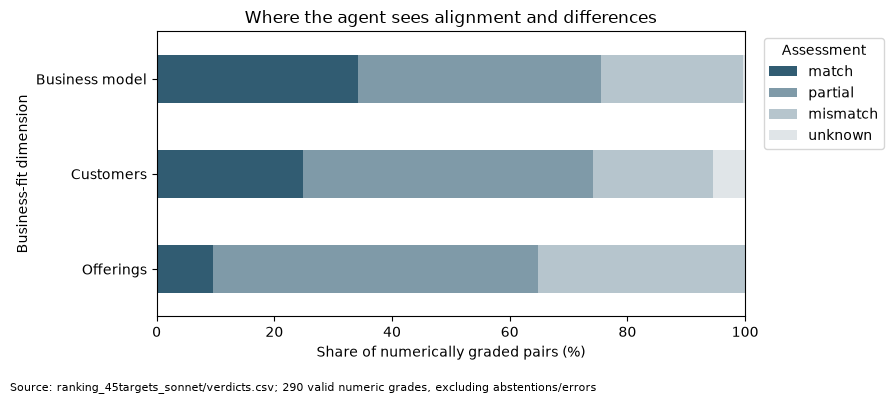

,match,partial,mismatch,unknown
dimension,,,,
Offerings,28,160,102,0
Customers,72,143,59,16
Business model,99,120,70,1


Offerings                          Customers                          Business model                         
offering_fit     match partial mismatch unknown     match partial mismatch unknown          match partial mismatch unknown
human                                                                                                                     
0                  0.0    21.0     79.0       0       2.0    49.0     43.0     6.0           11.0    59.0     29.0     1.0
1                  5.0    78.0     18.0       0      28.0    54.0     11.0     6.0           38.0    37.0     25.0     0.0
2                 87.0    13.0      0.0       0      87.0    13.0      0.0     0.0           96.0     4.0      0.0     0.0

In [8]:
import matplotlib.pyplot as plt
from datetime import datetime, timezone

# v1 peer_evaluation.ipynb section 7.2, on the agent's verdicts of the 293 pairs. v1a: the 0-2 rubric (v1's evaluator used 0-3).
analysis_dir = paths.out("05_agent_grading") / "fit_charts" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
analysis_dir.mkdir(parents=True, exist_ok=True)      # copies; the charts live in this notebook
pair_results = pd.read_csv(paths.path(cur["agent_grading"]["run"]) / "verdicts.csv", dtype={"target": str, "comp": str})
pair_results["judge_score"] = pd.to_numeric(pair_results["score"], errors="coerce")
ok = pair_results["status"].eq("ok")
graded_results = pair_results.loc[ok & pair_results.judge_score.notna()].copy()
num_graded, total = len(graded_results), len(pair_results)
score_counts = graded_results.judge_score.value_counts().reindex([0, 1, 2], fill_value=0)
insufficient = int((ok & pair_results.judge_score.isna()).sum())
failed = int((~ok).sum())

outcome_counts = pd.Series([*score_counts.tolist(), insufficient, failed],
                           index=["0: Not peer", "1: Adjacent", "2: Direct", "Insufficient\nevidence", "Failed /\ninvalid"],
                           name="pairs")
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(outcome_counts.index, outcome_counts.values, color="slategray")
ax.bar_label(bars, padding=3)
ax.set(title="Agent outcomes for Barbara's 293 B3 pairs", xlabel="Outcome", ylabel="Number of pairs")
ax.set_ylim(0, max(outcome_counts.max() * 1.15, 1))
fig.text(0.01, 0.01, f"Source: ranking_45targets_sonnet/verdicts.csv; all {total} pairs", fontsize=8)
fig.tight_layout(rect=(0, .05, 1, 1))
fig.savefig(analysis_dir / "outcomes.png", dpi=160)
plt.show()

fit_counts = pd.DataFrame({
    label: graded_results[col].value_counts().reindex(["match", "partial", "mismatch", "unknown"], fill_value=0)
    for col, label in [("offering_fit", "Offerings"), ("customer_fit", "Customers"),
                       ("business_model_fit", "Business model")]
}).T
if num_graded:
    fig, ax = plt.subplots(figsize=(9, 4))
    (fit_counts / num_graded * 100).plot.barh(stacked=True, ax=ax,
        color=["#315c72", "#7f9aa8", "#b6c5cd", "#e0e5e8"])
    ax.set(title="Where the agent sees alignment and differences", xlabel="Share of numerically graded pairs (%)",
           ylabel="Business-fit dimension", xlim=(0, 100))
    ax.legend(title="Assessment", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.text(.01, .01, f"Source: ranking_45targets_sonnet/verdicts.csv; {num_graded} valid numeric grades, excluding abstentions/errors", fontsize=8)
    fig.tight_layout(rect=(0, .05, 1, 1))
    fig.savefig(analysis_dir / "fit_dimensions.png", dpi=160, bbox_inches="tight")
    plt.show()
display(fit_counts.rename_axis("dimension"))
# v1a: the same fit counts split by Barbara's grade, to see which dimension the human grade follows
human = pair_results.merge(cohorts.load("dev_293")[["target_id", "comp_id", "grade"]], how="left", left_on=["target", "comp"], right_on=["target_id", "comp_id"])["grade"].set_axis(pair_results.index)
if human is not None:
    hf = graded_results.assign(human=human.reindex(graded_results.index))
    display(pd.concat({label: pd.crosstab(hf["human"], hf[col], normalize="index").mul(100).round(0)
                        .reindex(columns=["match", "partial", "mismatch", "unknown"], fill_value=0)
                        for col, label in [("offering_fit", "Offerings"), ("customer_fit", "Customers"),
                                           ("business_model_fit", "Business model")]}, axis=1))


**Reading.**
- **Outcomes:** the agent grades 290 of the 293 pairs (107 not peer, 157 adjacent, 26 direct) and finds too little
  evidence for 3.
- **Dimensions:** offerings are rarely a full match (28 of 290) and mostly partial (160); business model matches
  most often (99).
- **Against Barbara's grade:** her direct peers are a match on all three dimensions 87-96% of the time. Her
  non-peers are an offering mismatch 79% of the time but a customer mismatch only 43%, and her adjacent peers are
  mostly a partial offering match (78%). The offering dimension follows her grade most closely.


## 4. Checks

In [9]:
import agent_loop as al
saved_dir = sorted((run / "ranking").glob("2*"))[-1]
saved = pd.read_csv(saved_dir / "ranking.csv", dtype={"target": str, "comp": str})
cols = ["target", "comp", "coverage", "observed_similarity", "evidence_points", "e_rank", "final_rank"]
checks.add("ranking rebuilds exactly from the verdicts", ranked[cols].reset_index(drop=True).equals(saved[cols].reset_index(drop=True)),
           saved_dir.name)
old = json.loads((saved_dir / "eval.json").read_text())["eval"]
checks.add("ranking evaluation reproduces v1 (88.6% final order)", json.loads(json.dumps(ev)) == old,
           f"final top-3 pairwise {ev['by_k'][3]['final (agent, then S)']['pairwise_accuracy']}")
checks.add("saved instructions = the agent loop's prompt text", (run / "instructions.txt").read_text(encoding="utf-8") == al.INSTRUCTIONS)
checks.add("run settings = current.toml", config["prompt_version"] == cur["agent_grading"]["prompt_version"] == al.PROMPT_VERSION
           and config["facet_scores"] == cur["agent_grading"]["facet_scores"] and config["model"] == cur["agent_grading"]["model"])
checks.add("every dev_293 pair has a verdict", len(d) == 293 and v["status"].eq("ok").all())
checks.show()

5/5 checks pass


,check,result,detail
0,ranking rebuilds exactly from the verdicts,pass,20261113T060740Z
1,ranking evaluation reproduces v1 (88.6% final order),pass,final top-3 pairwise 0.886
2,saved instructions = the agent loop's prompt text,pass,
3,run settings = current.toml,pass,
4,every dev_293 pair has a verdict,pass,


## 5. History (v1)

- **11-05 (`gold*`, `round2*`):** prompt `2026-11-05a`, then `2026-11-05b`; round-1 golden set 31/32 exact with the
  reviewers' majority (one-shot Sol 26/32). Facet context switched from Haiku to Sonnet fills (Yifan's check).
- **11-06 (`round3_sonnet`):** the 262 round-3 pairs.
- **11-12/13 (`ranking_*`):** facet scores and the C/S/E ranking; `ranking_45targets_sonnet` is the current run.
- **11-17 (Fiona, `direct_peers`):** Barbara's 90 direct-peer pairs; the 24 in-universe pairs are in
  `10_final_holdout`, the 66 external pairs are left out of v1a.
- Every run's raw steps stay in `outputs-local/v1/agent_loop/`; the pair ledger (06) counts all 18 runs.